# 04 — Predicting Case Counts from Wastewater

**Project:** Machine Learning vs Regression for COVID-19 Case Prediction via Wastewater-Based Epidemiology
**Author:** Sebastian Munteanu · Department of Mathematical Sciences, University of Bath

---

The first three notebooks built a dataset. This one uses it to answer the question the project exists to answer: can the concentration of SARS-CoV-2 RNA in an area's wastewater be used to predict how many COVID-19 cases that area will record, and does a machine learning method do it better than ordinary regression?

## What is being measured, and why

People infected with SARS-CoV-2 shed fragments of viral RNA in their faeces, whether or not they have symptoms and whether or not they ever take a test. Those fragments travel through the sewer network to a treatment works, where a sample of the untreated inflow can be taken and the concentration quantified by PCR, in gene copies per litre. Through 2021 the Environmental Monitoring for Health Protection programme did this at 269 works across England.

The reason anyone would want such a measurement is that a reported case only exists if someone chose to seek a test, was able to get one, and had the result recorded. All three of those changed repeatedly over the pandemic, so the case series measures testing behaviour as much as it measures infection. A concentration in wastewater depends on none of it.

The difficulty is that the two things are measured on incompatible maps. Wastewater is sampled at treatment works, whose catchments follow the sewer network; cases are reported by local authority, whose boundaries are administrative. One works can serve parts of several authorities and one authority can be served by several works. Notebook 01 resolved this by expressing both in terms of small census areas, using the catchment overlaps published by Hoffmann et al. (2023), and computing for every works–authority pair the population living in both. That shared population is the weight used to attribute a works' reading to an authority.

What comes out is one row per local authority per day, from 1 June to 20 September 2021 — 307 authorities over 112 days. Each row carries the population-weighted concentration for that authority on days when a sample was taken, the case counts, characteristics of the authority such as density and deprivation, and vaccination uptake.

## The question needs a horizon attached

Asked informally — *given what the wastewater said, how many cases will there be?* — the question is missing something. Predicting tomorrow's cases from today's wastewater is a different problem from predicting next month's, and the two turn out to have opposite answers. So the question has to be posed as:

> Given wastewater and other information available $h$ days ago, how many cases are recorded today?

Here $h$ is the **forecast horizon**: the age of the oldest information the model may use. Every predictor in every model below is measured at least $h$ days before the day being predicted, so nothing unknown at forecast time can leak in. Rather than fix $h$ at some conventional value, this notebook treats it as the main experimental variable. The central comparison runs over $h \in \{7, 10, 14, 17, 21, 24, 28\}$ days; the supporting analyses, where a finer grid would cost time without adding insight, use $\{7, 14, 21, 28\}$.

Sections 2 to 5 build the model and say why it is specified as it is. Sections 6 to 10 report what it does. Sections 11 and 12 interpret the results and set out what they cannot support.


## Three decisions taken before any fitting

What the models can show is largely settled by three choices made in advance, so each is set out here with its alternative.

**What is predicted** is the number of cases recorded in an authority over the seven days ending on a given date, on a logarithmic scale. Seven-day totals rather than daily counts, because daily counts carry a strong day-of-week cycle — swabs are taken and processed less at weekends — which is a property of the testing system rather than of infection, and which no wastewater measurement could ever predict. Logarithms because case counts differ by more than two orders of magnitude across authorities, from a few dozen a week in the smallest districts to several thousand in the largest cities. On the natural scale an absolute error criterion is dominated by the biggest authorities, so an average across authorities would mostly reflect their population ranking. On the log scale an error of a given size means the same proportional miss in Rutland as in Birmingham.

**The unit of observation is an authority-day**, which invites an obvious objection: wastewater is not sampled every day, and roughly half of authority-days carry no measurement at all. Why not aggregate to the week, which is closer to the sampling frequency?

Because nothing is lost on the response side — cases are reported daily and the seven-day rolling total is defined on every one of them — and because a daily grid lets the horizon be varied finely, which matters when the horizon is the variable under study. A weekly grid would permit only four of the seven horizons examined, and would allow a forecast origin only on week boundaries, which in a sixteen-week study period is a real constraint on how many evaluation points exist. The qualification is that consecutive daily rows for the same authority share most of their information: the response is a seven-day rolling total, so adjacent days differ by two observations out of seven, and the predictor is smoothed over longer still. The effective number of independent observations is therefore far below the row count. That does not bias anything, but it means the row count must not be mistaken for precision. Section 4 quantifies the consequence and refits the model on a weekly grid to confirm nothing turns on the choice.

**Past case counts are excluded from the main models.** This is worth spelling out, because including them would answer a different question. With lagged cases among the predictors, the model is asked whether wastewater improves a forecast that already knows the authority's recent case history — a fair question, but one that flatters the competition, since a lagged case count is an extremely strong predictor of a current one and also encodes almost everything static about a place. Without them, the model is asked how well one could do knowing only wastewater and public information about the area. That is the situation wastewater surveillance exists for; its whole value proposition is that it works where case ascertainment is absent, delayed or distorted.

Lagged cases therefore appear only as comparators. They form the persistence benchmark of §5, which is the standard the wastewater models must beat, and they are fitted as a model in their own right — reported in §6 and analysed in §8 — so the incremental value of wastewater given case data can be quantified too. Neither role puts a case count inside anything described here as a wastewater model.


## 1. Setup


In [1]:
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from sklearn.metrics import mean_absolute_error
from xgboost import XGBRegressor
import warnings; warnings.filterwarnings('ignore')

PROJECT = Path.cwd()
if PROJECT.name == 'notebooks':
    PROJECT = PROJECT.parent
DATA, OUT = PROJECT / 'data', PROJECT / 'output'
OUT.mkdir(exist_ok=True)
pd.set_option('display.width', 170)

panel = pd.read_csv(OUT / 'rna_cases_panel.csv', parse_dates=['date'])
cov   = pd.read_csv(OUT / 'ltla_covariates.csv').drop(columns=['LAD21NM','AREALHECT','ltla_pop'])
vacc  = pd.read_csv(OUT / 'ltla_vaccination.csv', parse_dates=['date'])

df = (panel.sort_values(['LAD21CD','date']).reset_index(drop=True)
           .merge(cov, on='LAD21CD')
           .merge(vacc, on=['LAD21CD','date'], how='left'))
df['log_pop'] = np.log10(df.ltla_pop)
df['y'] = np.log10(df.cases_roll7_sum.replace(0, np.nan))     # the response

Z = ['log_pop','log_density','imd_score','pct_65plus','pct_under18','median_age']
print(f'{len(df):,} authority-days | {df.LAD21CD.nunique()} authorities | '
      f'{df.date.min().date()} to {df.date.max().date()}')
print(f'authority-days with a same-day wastewater measurement: {100*df.log10_rna_geom.notna().mean():.0f}%')
print(f'median catchment coverage of an authority-day: {df.coverage_frac.median():.2f}')

_v = df.groupby('date').vacc_dose2_pct.median()
print(f'median second-dose uptake: {_v.iloc[0]:.0f}% on {_v.index[0].date()} '
      f'-> {_v.iloc[-1]:.0f}% on {_v.index[-1].date()}')
_r = 1e5 * df.cases_roll7_sum / df.ltla_pop
print(f'median authority 7-day case rate: {_r.median():.0f} per 100,000 '
      f'(quartiles {_r.quantile(.25):.0f} to {_r.quantile(.75):.0f})')

34,384 authority-days | 307 authorities | 2021-06-01 to 2021-09-20
authority-days with a same-day wastewater measurement: 52%
median catchment coverage of an authority-day: 0.58
median second-dose uptake: 42% on 2021-06-01 -> 70% on 2021-09-20
median authority 7-day case rate: 272 per 100,000 (quartiles 158 to 352)


## 2. Building the wastewater predictor

The raw measurement is a concentration at a works on a day when a sample happened to be taken. Two things stop it being used directly.

The first is sparsity. Sites are sampled a few times a week, so only about half of authority-days carry any reading at all; a model using same-day values could be fitted on at most half the data and could produce no forecast whatever on the rest. The second is noise. A single grab sample is a poor estimate of the day's average concentration — flow varies with rainfall, RNA degrades in transit at a rate depending on temperature and travel time, and the assay has its own run-to-run variability. Averaging over a window of $w$ days addresses both, filling the gaps while reducing noise roughly as $n^{-1/2}$ in the number of samples the window happens to contain.

Smoothing is applied to $\log_{10}$ concentration rather than to concentration itself. The two are not the same: by Jensen's inequality the mean of the logs sits below the log of the mean, and materially so for a quantity this skewed. Averaging on the log scale also keeps the predictor on the scale the model is linear in, and stops one high reading dominating a window.


In [2]:
def smooth(d, w):
    return d.groupby('LAD21CD')['log10_rna_geom'].transform(
               lambda s: s.rolling(w, min_periods=1).mean())

for w in (7, 14, 21, 28):
    cover = smooth(df, w).notna().mean()
    print(f'{w:>2}-day window: predictor defined on {100*cover:.1f}% of authority-days')

 7-day window: predictor defined on 95.9% of authority-days
14-day window: predictor defined on 96.0% of authority-days
21-day window: predictor defined on 96.0% of authority-days
28-day window: predictor defined on 96.0% of authority-days


How long the window should be is a trade-off rather than a fact. A longer one fills more gaps and averages away more noise, but responds more slowly — a 28-day mean cannot turn as fast as an epidemic can. The choice is made empirically below, on validation forecast origins only, so that it is not made on the data later used to report performance. Origins are defined in §5; the short version is that the fifteen forecast dates are split, the first seven used for decisions like this one and the last eight kept back. Alongside each average the table gives the standard deviation of the error across those origins, which sets the scale against which any difference between windows has to be read.


In [3]:
ORIGINS = pd.date_range('2021-08-01', '2021-09-12', freq='3D')
VAL, TEST = ORIGINS[:7], ORIGINS[7:]

def origin_errors(d, feats, origins, ycol='y'):
    # Fit up to each origin, score the following 7 days. Returns one error per origin.
    errs = []
    for o in origins:
        tr = d[d.date <= o].dropna(subset=feats + [ycol])
        te = d[(d.date > o) & (d.date <= o + pd.Timedelta(days=7))].dropna(subset=feats + [ycol])
        if len(te) < 100 or len(tr) < 500:
            continue
        f = sm.OLS(tr[ycol], sm.add_constant(tr[feats])).fit()
        errs.append(mean_absolute_error(te[ycol], f.predict(sm.add_constant(te[feats], has_constant='add'))))
    return np.array(errs)

def rolling_eval(d, feats, origins, ycol='y'):
    e = origin_errors(d, feats, origins, ycol)
    return e.mean() if len(e) else np.nan

rows = []
for w in (7, 14, 21, 28):
    d = df.assign(x=smooth(df, w))
    d['x_h'] = d.groupby('LAD21CD')['x'].shift(21)
    e = origin_errors(d, ['x_h'] + Z, VAL)
    rows.append({'window (days)': w, 'validation MAE': e.mean(),
                 'sd across origins': e.std(ddof=1)})
display(pd.DataFrame(rows).round(4))
print(f'{len(VAL)} validation origins, {len(TEST)} test origins held back')

,window (days),validation MAE,sd across origins
0,7,0.1043,0.0104
1,14,0.0968,0.0092
2,21,0.0940,0.0083
3,28,0.0925,0.0053


7 validation origins, 8 test origins held back


Twenty-one days is selected. Going from 7 to 21 removes about a tenth of the error, a gain of 0.0103; going on to 28 gains a further 0.0015, roughly a sixth as much and well inside the origin-to-origin spread, which runs from 0.005 to 0.010. Neither difference is large against that spread, but the first is at least of the same order as it and the second plainly is not. The four windows also order themselves consistently rather than erratically, the error falling monotonically and by decreasing amounts, which is the pattern expected once the benefit of extra averaging has largely been used up. Since the longer window is also the less responsive one, the shorter of two effectively equivalent choices is preferred.

## How the lag should enter

The obvious specification uses the smoothed concentration at a single lag, $x_{i,t-h}$, perhaps with a difference term to say whether the signal is rising or falling. There is no reason to expect the information about today's cases to sit at exactly one point in the past, though. Shedding begins within days of infection and continues for weeks, and a case is recorded at some variable interval after infection, so the relationship between concentration at lag $\ell$ and cases today is spread across a range of $\ell$. The standard treatment in that situation is a **distributed lag**: several lagged terms entering together, letting the data decide the weight on each.

Before choosing, it is worth looking at the shape directly. The regression below is fitted separately at each lag with covariates held constant, and the coefficient on concentration recorded. A 7-day smoothing window is used for this panel alone, so that neighbouring lags stay reasonably distinct — the 21-day window adopted above would blur three weeks of signal into every point and flatten the very structure the panel exists to show. What it describes is therefore the raw signal, not the predictor eventually used.


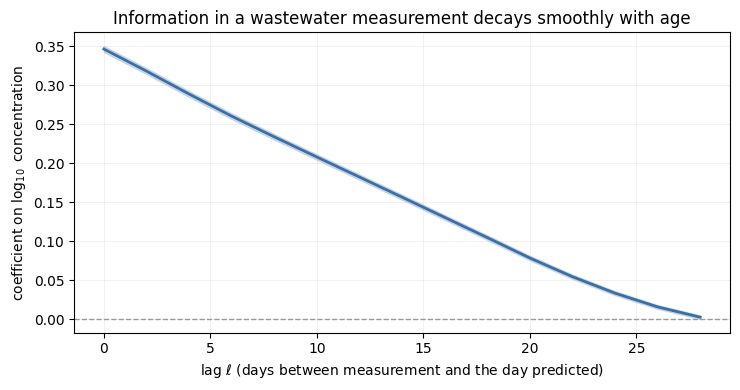

,lag,coefficient,std err
0,0,0.3465,0.0020
2,4,0.2889,0.0019
4,8,0.2340,0.0018
6,12,0.1825,0.0017
8,16,0.1309,0.0016
10,20,0.0788,0.0015
12,24,0.0337,0.0013
14,28,0.0030,0.0012


In [4]:
# A 7-day window is used HERE ONLY, so that neighbouring lags stay reasonably
# distinct. This panel is a diagnostic of the raw signal, not of the predictor
# adopted in 3.2, whose 21-day window would blur adjacent lags together.
d7 = df.assign(x=smooth(df, 7))
g = d7.groupby('LAD21CD')
prof = []
for L in range(0, 29, 2):
    dd = d7.assign(xl=g['x'].shift(L)).dropna(subset=['xl','y'] + Z)
    f = sm.OLS(dd.y, sm.add_constant(dd[['xl'] + Z])).fit()
    prof.append({'lag': L, 'coefficient': f.params['xl'], 'std err': f.bse['xl']})
prof = pd.DataFrame(prof)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(prof.lag, prof.coefficient, color='#3a6ea5', lw=2)
ax.fill_between(prof.lag, prof.coefficient - 2*prof['std err'],
                prof.coefficient + 2*prof['std err'], color='#3a6ea5', alpha=0.2)
ax.axhline(0, color='#999999', lw=1, ls='--')
ax.set(xlabel='lag $\\ell$ (days between measurement and the day predicted)',
       ylabel='coefficient on $\\log_{10}$ concentration',
       title='Information in a wastewater measurement decays smoothly with age')
ax.grid(alpha=0.25, lw=0.5); fig.tight_layout(); plt.show()
display(prof[prof.lag % 4 == 0].round(4))

The coefficient falls smoothly and monotonically from about 0.35 at lag zero to essentially zero at 28 days, with no secondary peak anywhere. Two conclusions follow. There is no privileged lag at which wastewater is informative — it is informative across a broad range and decreasingly so, which is the argument for a distributed lag over a single term. And the decay is itself a result worth reporting: a wastewater measurement carries useful information about incidence for roughly three to four weeks and very little after that, a timescale not obvious in advance.

The specification adopted uses four terms, at lags $h$, $h+7$, $h+14$ and $h+21$, each entering separately so the fit determines their relative weight. The comparison below is against the single-lag-plus-difference alternative, on the validation origins.


In [5]:
LAGS = [0, 7, 14, 21]
X = [f'x{k}' for k in LAGS]

def build(h, w=21, vacc_extra=14):
    # Assemble the design matrix for horizon h. Every regressor is at least h days old.
    d = df.assign(x=smooth(df, w))
    g = d.groupby('LAD21CD')
    for k in LAGS:
        d[f'x{k}'] = g['x'].shift(h + k)                 # distributed lag on wastewater
    d['x_single'] = d['x0']                              # single-lag alternative
    d['x_delta']  = d['x0'] - g['x'].shift(h + 14)       # its 14-day difference term
    d['y_h'] = g['y'].shift(h)                           # persistence benchmark only
    d['v1']  = g['vacc_dose1_pct'].shift(h + vacc_extra) # vaccination, see 4.2
    d['v2']  = g['vacc_dose2_pct'].shift(h + vacc_extra)
    return d
V = ['v1','v2']

rows = []
for h in (7, 14, 21, 28):
    d = build(h)
    rows.append({'horizon': h,
                 'single lag + difference': rolling_eval(d, ['x_single','x_delta'] + Z, VAL),
                 'distributed lag (4 terms)': rolling_eval(d, X + Z, VAL)})
r = pd.DataFrame(rows)
r['improvement %'] = 100*(r['single lag + difference'] - r['distributed lag (4 terms)'])/r['single lag + difference']
display(r.round(4))

,horizon,single lag + difference,distributed lag (4 terms),improvement %
0,7,0.1248,0.1074,13.9640
1,14,0.1034,0.0967,6.4731
2,21,0.0903,0.0899,0.4724
3,28,0.0883,0.0838,5.1227


The distributed lag is better at all four horizons. Its margin is largest at one week, where a single three-week-old measurement is least adequate alone, and smallest at three weeks, where the two are effectively tied; it is not monotone in the horizon, which is unsurprising when each figure averages seven origins with a standard deviation of about 0.01 between them.

It also disposes of the difference term, and does so by argument rather than by measurement. A difference over 14 days is the contrast $x_{i,t-h} - x_{i,t-h-14}$, which is a linear combination of terms the model already contains, so there is no separate quantity left for it to contribute — and the arbitrary choice of 14 days rather than 7 or 21 disappears along with it. The distributed lag is used from here on.


## 3. What else goes into the model

A wastewater concentration is a measurement about a place, and the same concentration does not imply the same incidence everywhere. A dense inner-city authority with a young population, high deprivation and many residents who cannot work from home is not epidemiologically comparable to a sparse, affluent rural district with an older population, even when their wastewater reads identically — nor are the two comparable in how completely their residents sought testing.

The covariates $\mathbf{z}_i$ are the model's only way of telling them apart. Built in notebook 03, they are $\log_{10}$ population, $\log_{10}$ population density, the Index of Multiple Deprivation score, the shares of residents under 18 and over 65, and median age. All were aggregated onto 2021 authority boundaries from small census areas using the same population weighting as the wastewater link, so no boundary-vintage mismatch is introduced.

Population is in there because the response is a count rather than a rate. If cases scale roughly in proportion to population, its coefficient should come out near one, meaning the model has recovered a rate specification while estimating the scaling instead of imposing it. Section 9 checks whether it does.

## Vaccination, and why its lag is not $h$

Vaccination uptake is the only covariate that moves over time within an authority, and over this period it moved a great deal: median second-dose coverage across authorities rose from 42% on 1 June to 70% on 20 September.

Lagging it by the same $h$ as the wastewater would be a mistake, because the two lags mean different things. The wastewater lag is a constraint on data availability — it represents what was known at forecast time. Vaccination has that constraint too, but also a biological one: protection develops over roughly two weeks after a dose, so the uptake figure relevant to today's incidence is the figure from at least a fortnight earlier. The two compound rather than coincide, and vaccination is entered at $h + 14$ days. How much the choice matters is examined below, again on validation origins.


In [6]:
rows = []
for h in (7, 14, 21, 28):
    row = {'horizon': h}
    for extra in (0, 14, 28):
        d = build(h, vacc_extra=extra)
        row[f'vaccination at h+{extra}'] = rolling_eval(d, X + Z + V, VAL)
    rows.append(row)
vt = pd.DataFrame(rows)
display(vt.round(4))
sp = origin_errors(build(21, vacc_extra=14), X + Z + V, VAL).std(ddof=1)
print(f'for scale: at h=21 the error varies by sd {sp:.4f} from one origin to the next,')
_row = vt.loc[vt.horizon == 21, [c for c in vt if c != 'horizon']].values.ravel()
print(f'against a spread of {_row.max() - _row.min():.4f} across the three lag choices')

,horizon,vaccination at h+0,vaccination at h+14,vaccination at h+28
0,7,0.1081,0.1082,0.1002
1,14,0.0972,0.0988,0.0985
2,21,0.0895,0.0900,0.0880
3,28,0.0821,0.0825,0.0758


for scale: at h=21 the error varies by sd 0.0108 from one origin to the next,
against a spread of 0.0020 across the three lag choices


Three weeks serves throughout the notebook as a reference horizon whenever a single figure is wanted: it sits in the middle of the range examined, and §6 shows it to be roughly where the wastewater and persistence forecasts change places. At that horizon the three lag choices span 0.0020 in MAE, against a standard deviation of 0.0108 from one forecast origin to the next — differences about a fifth the size of the noise in the measurement used to compare them. Predictive performance does not settle the question.

Such tendency as there is runs towards the longer lags rather than the shorter, which is at least consistent with the physiological argument and inconsistent with entering vaccination at the same lag as the wastewater. The $h+14$ specification is kept: it is what the biology suggests, it was fixed before the table was computed, and switching to $h+28$ on a margin this far inside the noise would be selecting on chance. The table is here so the choice is visible rather than buried.


## 4. The model, and what it assumes

For authority $i$ on day $t$:

$$
\log_{10} C_{it} \;=\; \beta_0 \;+\; \sum_{k \in \{0,7,14,21\}} \beta_k\, x_{i,\,t-h-k} \;+\; \mathbf{z}_i^{\top}\boldsymbol{\gamma} \;+\; \mathbf{v}_{i,\,t-h-14}^{\top}\boldsymbol{\delta} \;+\; \varepsilon_{it}
$$

where $C_{it}$ is the seven-day case total, $x$ the 21-day trailing mean of $\log_{10}$ concentration, $\mathbf{z}_i$ the time-invariant authority covariates and $\mathbf{v}$ vaccination uptake. Estimation is by ordinary least squares. A gradient-boosted tree ensemble is fitted on the identical design matrix in §10 as the machine learning comparator.

Least squares gives unbiased and consistent estimates under fairly weak conditions — the model linear in its parameters, the errors uncorrelated with the regressors — and none of them require the errors to be normally distributed. Normality governs the exact small-sample distribution of test statistics, which at tens of thousands of observations the central limit theorem makes largely beside the point. Two assumptions are worth examining rather than asserting, though: the shape of the error distribution, and, more seriously, whether the errors are independent at all.


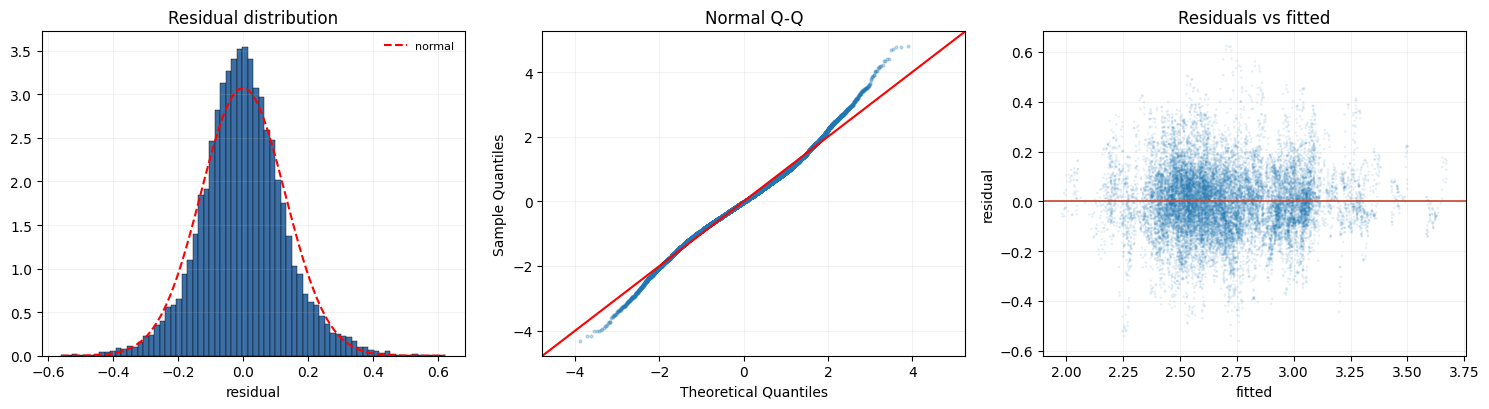

n = 20,459   sd = 0.1299
skewness = +0.142   excess kurtosis = +1.097

empirical vs normal quantiles:
     1%   -0.3233   vs   -0.3021
     5%   -0.2092   vs   -0.2136
    50%   -0.0026   vs   +0.0000
    95%   +0.2197   vs   +0.2136
    99%   +0.3459   vs   +0.3021

Jarque-Bera = 1,094, p = 3.2e-238


In [7]:
H_REF = 21
d = build(H_REF)
dd = d.dropna(subset=X + V + Z + ['y'])
fit = sm.OLS(dd.y, sm.add_constant(dd[X + V + Z])).fit()
res = fit.resid

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].hist(res, bins=70, color='#3a6ea5', edgecolor='k', linewidth=0.3, density=True)
xs = np.linspace(res.min(), res.max(), 200)
axes[0].plot(xs, stats.norm.pdf(xs, res.mean(), res.std()), 'r--', lw=1.5, label='normal')
axes[0].set(xlabel='residual', title='Residual distribution'); axes[0].legend(frameon=False, fontsize=8)
sm.qqplot(res, line='45', fit=True, ax=axes[1], markersize=2, alpha=0.25)
axes[1].set_title('Normal Q-Q')
axes[2].scatter(fit.fittedvalues, res, s=3, alpha=0.12, edgecolor='none')
axes[2].axhline(0, color='#c2452d', lw=1.2)
axes[2].set(xlabel='fitted', ylabel='residual', title='Residuals vs fitted')
for a in axes: a.grid(alpha=0.25, lw=0.5)
fig.tight_layout(); plt.show()

print(f'n = {len(res):,}   sd = {res.std():.4f}')
print(f'skewness = {stats.skew(res):+.3f}   excess kurtosis = {stats.kurtosis(res):+.3f}')
print('\nempirical vs normal quantiles:')
for q in (0.01, 0.05, 0.5, 0.95, 0.99):
    print(f'  {q:>5.0%}   {np.quantile(res, q):+.4f}   vs   {stats.norm.ppf(q, res.mean(), res.std()):+.4f}')
jb, jbp = stats.jarque_bera(res)
print(f'\nJarque-Bera = {jb:,.0f}, p = {jbp:.3g}')

The residuals come out close to symmetric, with skewness 0.14, and with tails heavier than normal at excess kurtosis 1.10. The 1st percentile sits 7% further from the centre than a normal distribution would put it and the 99th sits 15% further, so the excess is real but modest and slightly greater in the upper tail. Jarque–Bera rejects normality overwhelmingly, but at $n>20{,}000$ such tests reject on any departure however slight, and the quantile comparison is the more informative summary.

Little follows from this. The coefficient estimates are unaffected. The heavier tails are a reason to score forecasts by mean absolute error rather than root mean squared error, since squared error would let a handful of extreme residuals dominate the comparison, and MAE is used throughout. The residuals-versus-fitted panel shows no systematic curvature, so the linear-in-logs form is not obviously misspecified.

## The assumption that does not hold

Least squares inference assumes every observation contributes independent information, and here it plainly does not. The same 307 authorities are observed every day; the response is a seven-day rolling total, so consecutive days share six of their seven constituent days; the predictor is smoothed over 21. Residuals are therefore strongly autocorrelated within an authority, and correlated across authorities on the same day through the shared national trajectory.

The effect is that the effective sample size is far below the row count and the standard errors ordinary least squares reports are far too small. Point estimates stay consistent, so nothing in the forecasting results depends on this, but any interval or $p$-value taken from naive output is worthless. Section 9 handles it by clustering the covariance estimator rather than by hoping it does not matter, and the size of the correction there is a good indication of how badly the naive version misleads.

The same reasoning explains why the daily grid of §1 is a presentational convenience rather than extra information. The check below refits on a weekly grid to confirm nothing substantive rests on it.


In [8]:
dw = d.dropna(subset=X + Z + ['y']).copy()
dw['week'] = dw.date.dt.to_period('W').dt.start_time
weekly = (dw.groupby(['LAD21CD','week'], as_index=False)[X + Z + ['y']].mean()
            .rename(columns={'week':'date'}))

def rolling_eval_small(data, feats):
    errs = []
    for o in TEST:
        tr = data[data.date <= o].dropna(subset=feats + ['y'])
        te = data[(data.date > o) & (data.date <= o + pd.Timedelta(days=7))].dropna(subset=feats + ['y'])
        if len(te) < 40 or len(tr) < 300: continue
        f = sm.OLS(tr.y, sm.add_constant(tr[feats])).fit()
        errs.append(mean_absolute_error(te.y, f.predict(sm.add_constant(te[feats], has_constant='add'))))
    return np.mean(errs) if errs else np.nan

print(f'daily grid : {len(dw):,} rows, MAE {rolling_eval(d, X + Z, TEST):.4f}')
print(f'weekly grid: {len(weekly):,} rows, MAE {rolling_eval_small(weekly, X + Z):.4f}')
print('\nThe weekly figure is the higher of the two, but the two targets are not identical:')
print('the weekly response is a within-week average and so is smoother than any single day.')
print('The comparison establishes that no conclusion turns on the daily grid, which is used')
print('for the finer horizon resolution it permits, not because it holds more information.')

daily grid : 20,459 rows, MAE 0.0971
weekly grid: 3,265 rows, MAE 0.1041

The weekly figure is the higher of the two, but the two targets are not identical:
the weekly response is a within-week average and so is smoother than any single day.
The comparison establishes that no conclusion turns on the daily grid, which is used
for the finer horizon resolution it permits, not because it holds more information.


## 5. How performance is judged

Any model has to be compared against something, and comparing against an intercept-only model would settle nothing: the response is highly autocorrelated, so almost anything beats an unconditional mean. The benchmark used throughout is **persistence** — predict today's seven-day case total to be whatever it was $h$ days ago, with nothing estimated at all. At short horizons this is a demanding standard precisely because case counts move slowly, and it is the right one, because the claim that wastewater is useful is a claim that it tells you something you did not already know.

Performance is assessed by rolling-origin evaluation. For each origin date the model is fitted using only observations on or before it and scored on the following seven days, so nothing after the origin influences the fit, and results are averaged across origins. The alternative of assigning rows to training and test sets at random, as Morvan et al. (2022) do, would mislead badly here: because the response moves slowly, a randomly held-out authority-day has its immediate neighbours in the training set, and the model need only interpolate between two nearly identical values. That is not forecasting, and it produces error figures far better than any prospective use would achieve.

Origins run every three days from 1 August to 12 September 2021. The first seven are validation origins — the smoothing window of §2, the lag structure of §2 and the vaccination lag of §3 were chosen on these and on nothing else. The last eight are test origins, and every performance figure from §6 onwards comes from them with the specification already fixed. The one earlier use of a test origin is the weekly-grid check above, which examines a consequence of the design rather than choosing between candidates. Origins start in August so that even the longest horizon has enough training history behind it: at $h=28$ the regressors need 49 days.

The separation matters because choosing among specifications on the same data used to report error biases the reported figure downwards by an amount nobody can estimate afterwards. Eight test origins make for noisy figures, but at least not optimistic ones.

Error is mean absolute error on the $\log_{10}$ scale. Since the response is logged, an error of $m$ means being out by a multiplicative factor of $10^{m}$, which means the same thing in a small district as in a large city:

| MAE | multiplicative error | in words |
|---|---|---|
| 0.05 | 1.12 | typically 12% out |
| 0.10 | 1.26 | typically 26% out |
| 0.15 | 1.41 | typically 41% out |
| 0.20 | 1.58 | typically 58% out |


## 6. Forecast error against horizon

Six models are compared at each horizon.

| Model | Information used |
|---|---|
| Persistence | The case total $h$ days ago. Nothing fitted. |
| Covariates only | $\mathbf{z}_i$ alone. A floor: it can only predict a constant per authority. |
| Wastewater only | The four lagged concentration terms, with nothing about the authority. |
| Wastewater + covariates | The specification of §4 without vaccination. Uses no case data at all. |
| Wastewater + covariates + vaccination | The full specification. |
| Case history + covariates | Lagged cases in place of wastewater, for the comparison in §8. |


In [9]:
def persistence(d, origins=TEST):
    errs = []
    for o in origins:
        te = d[(d.date > o) & (d.date <= o + pd.Timedelta(days=7))].dropna(subset=['y','y_h'])
        if len(te) >= 100:
            errs.append(mean_absolute_error(te.y, te.y_h))
    return np.mean(errs)

HORIZONS = [7, 10, 14, 17, 21, 24, 28]
rows = []
for h in HORIZONS:
    d = build(h)
    rows.append({'horizon': h,
                 'persistence'                : persistence(d),
                 'covariates only'            : rolling_eval(d, Z, TEST),
                 'wastewater only'            : rolling_eval(d, X, TEST),
                 'wastewater + cov'           : rolling_eval(d, X + Z, TEST),
                 'wastewater + cov + vacc'    : rolling_eval(d, X + Z + V, TEST),
                 'case history + cov'         : rolling_eval(d, ['y_h'] + Z, TEST)})
H = pd.DataFrame(rows)
H['covariate gain %']    = 100*(H['wastewater only'] - H['wastewater + cov'])/H['wastewater only']
# The full specification of 5.1 is the model reported, fixed in advance -- not
# whichever of the two scored better on the test origins.
H['vs persistence %']    = 100*(H.persistence - H['wastewater + cov + vacc'])/H.persistence
display(H.round(4))

,horizon,persistence,covariates only,wastewater only,wastewater + cov,wastewater + cov + vacc,case history + cov,covariate gain %,vs persistence %
0,7,0.0683,0.2309,0.2155,0.0943,0.0901,0.0723,56.2177,-31.8586
1,10,0.0743,0.2309,0.2186,0.0937,0.0904,0.0778,57.1467,-21.5913
2,14,0.0753,0.2309,0.2230,0.0943,0.0931,0.0797,57.7166,-23.6654
3,17,0.0809,0.2309,0.2259,0.0951,0.0949,0.0836,57.9171,-17.3690
4,21,0.0939,0.2309,0.2308,0.0971,0.0972,0.0892,57.9563,-3.5089
5,24,0.1017,0.2309,0.2284,0.0955,0.0957,0.0912,58.1624,5.9039
6,28,0.1071,0.2309,0.2211,0.0921,0.0921,0.0921,58.3459,14.0715


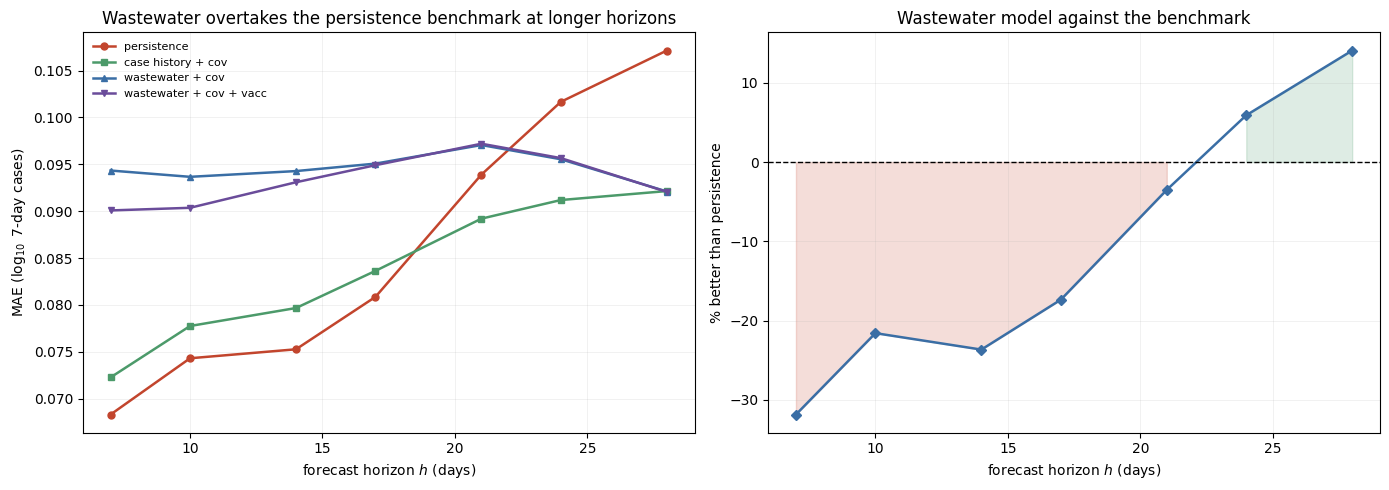

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
for col, c, m in [('persistence','#c2452d','o'), ('case history + cov','#4c9a6a','s'),
                  ('wastewater + cov','#3a6ea5','^'), ('wastewater + cov + vacc','#6a4c9a','v')]:
    ax.plot(H.horizon, H[col], marker=m, color=c, lw=1.8, ms=5, label=col)
ax.set(xlabel='forecast horizon $h$ (days)', ylabel='MAE ($\\log_{10}$ 7-day cases)',
       title='Wastewater overtakes the persistence benchmark at longer horizons')
ax.legend(fontsize=8, frameon=False); ax.grid(alpha=0.25, lw=0.5)

ax = axes[1]
ax.plot(H.horizon, H['vs persistence %'], marker='D', color='#3a6ea5', lw=1.8, ms=5)
ax.axhline(0, color='k', ls='--', lw=1)
ax.fill_between(H.horizon, 0, H['vs persistence %'], where=H['vs persistence %']>0, alpha=0.18, color='#4c9a6a')
ax.fill_between(H.horizon, 0, H['vs persistence %'], where=H['vs persistence %']<=0, alpha=0.18, color='#c2452d')
ax.set(xlabel='forecast horizon $h$ (days)', ylabel='% better than persistence',
       title='Wastewater model against the benchmark')
ax.grid(alpha=0.25, lw=0.5)
fig.tight_layout(); plt.show()

At short horizons persistence is much the better of the two, which is a statement about the response rather than a failure of the predictor: over one week an authority's case total stays close to what it was, so its own recent value is an excellent forecast and little else is needed.

As the horizon lengthens the persistence error climbs steadily, because the autocorrelation of the response decays. The wastewater model's error stays nearly flat over the same range, since its four lagged terms span three weeks of signal and moving the horizon shifts the whole window back without much changing how much information it holds. So the two curves cross. At 21 days the wastewater model is still 3.5% behind; at 24 days it is 5.9% ahead, putting the crossing between three weeks and three and a half. By four weeks it is 14% ahead, using no case data whatever. Section 10 shows this crossing to be a feature of the linear model specifically.

What drives this is a difference in how fast each source goes stale. Case counts are highly informative when recent and lose value quickly. Wastewater is less informative at any given moment, as the lag profile in §2 showed, but decays more slowly, because it measures shedding directly rather than inferring infection through a testing process whose intensity is itself varying.

Two cautions about the magnitudes. The test set is eight origins inside a three-week window of a single epidemic wave, and §2 measured the error at a single origin varying with a standard deviation of order 0.01 — comparable to the differences being reported. What the analysis supports is the direction and the mechanism, not the exact percentages. And the crossing point belongs to this wave and this testing regime; a period of different testing intensity need not put it in the same week.


## 7. What the covariates contribute

The covariates-only row above repays attention. Every element of $\mathbf{z}_i$ is time-invariant, so a model containing only covariates predicts one fixed number per authority and cannot move at all; its error is identical at every horizon by construction.

Wastewater alone does little better. It has a small edge at the shortest horizons — 0.2155 against 0.2309 at one week — which has disappeared entirely by three weeks. Both sit between 0.215 and 0.231 throughout, roughly two and a half times the error of the two together.


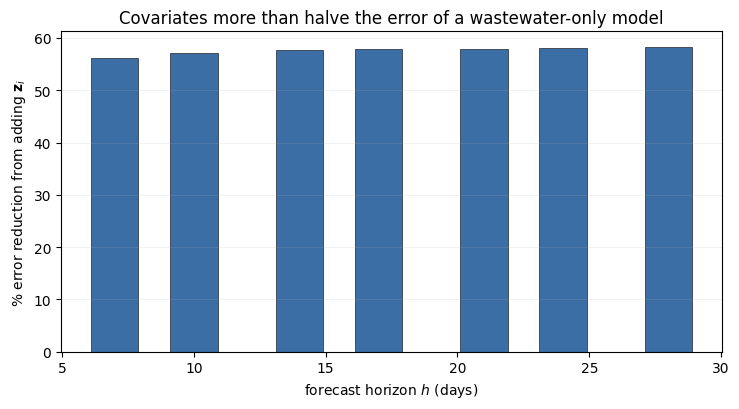

,model,MAE,change
0,wastewater only,0.2308,NaN
1,+ population,0.0987,-0.1321
2,+ density,0.0997,0.0010
3,+ deprivation,0.0968,-0.0029
4,+ age structure,0.0971,0.0003
5,+ vaccination,0.0972,0.0001


In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.bar(H.horizon, H['covariate gain %'], width=1.8, color='#3a6ea5', edgecolor='k', linewidth=0.4)
ax.set(xlabel='forecast horizon $h$ (days)', ylabel='% error reduction from adding $\\mathbf{z}_i$',
       title='Covariates more than halve the error of a wastewater-only model')
ax.grid(axis='y', alpha=0.25, lw=0.5); fig.tight_layout(); plt.show()

d = build(21)
blocks = {'wastewater only': X, '+ population': X + ['log_pop'],
          '+ density': X + ['log_pop','log_density'],
          '+ deprivation': X + ['log_pop','log_density','imd_score'],
          '+ age structure': X + Z, '+ vaccination': X + Z + V}
rows, prev = [], None
for name, F in blocks.items():
    m = rolling_eval(d, F, TEST)
    rows.append({'model': name, 'MAE': m, 'change': np.nan if prev is None else m - prev})
    prev = m
display(pd.DataFrame(rows).round(4))

Adding $\mathbf{z}_i$ cuts the error of a wastewater-only model by 56 to 58% at every horizon. Population is much the largest single contributor, which follows directly from the response being a count: without it the model cannot tell a large authority from a small one at all. Deprivation is the largest of the genuinely structural covariates.

The two blocks are complementary rather than competing. The covariates fix the level appropriate to each authority; the wastewater terms, being the only regressors that move over time, determine the movement around that level. At the reference horizon neither alone gets below 0.23, while together they reach 0.097 — and at four weeks, 0.092.


## 8. Two checks on the result

Section 6 compares wastewater against persistence, which is the right test for an authority with no case ascertainment. Two further comparisons bound what that result can be taken to mean.

The first asks whether wastewater adds anything where case data does exist. If recent case counts are already available, is the sampling and laboratory cost worth paying? The comparison is between a model using lagged cases and covariates, and the same model with the wastewater terms added.


In [12]:
rows = []
for h in (7, 14, 21, 28):
    d = build(h)
    hist = rolling_eval(d, ['y_h'] + Z, TEST)
    both = rolling_eval(d, ['y_h'] + X + Z, TEST)
    rows.append({'horizon': h, 'case history + cov': hist,
                 'case history + wastewater + cov': both,
                 'wastewater adds %': 100*(hist - both)/hist})
display(pd.DataFrame(rows).round(4))

,horizon,case history + cov,case history + wastewater + cov,wastewater adds %
0,7,0.0723,0.0707,2.2229
1,14,0.0797,0.0860,-7.9289
2,21,0.0892,0.0971,-8.8658
3,28,0.0921,0.0919,0.3040


The answer does not favour wastewater. Adding the concentration terms to a model that already holds recent case counts improves the forecast slightly at one week and at four, and makes it about 8 to 9% worse at two and three weeks — the pattern expected when extra regressors carry little information but still have to be estimated from a short training period. Where case surveillance exists and is timely, then, wastewater is not demonstrably worth adding, and its case rests entirely on the situation where ascertainment is absent or unreliable.

The second check is more searching. Both the wastewater series and the national epidemic trajectory move smoothly over this study period, and any regressor correlated with that trajectory will improve forecasts whether or not it says anything about an individual authority. To test for this, vaccination uptake — an unrelated measurement that also varies smoothly over the same window — is substituted for the wastewater terms.


In [13]:
rows = []
for h in (7, 14, 21, 28):
    d = build(h)
    rows.append({'horizon': h,
                 'wastewater + covariates'      : rolling_eval(d, X + Z, TEST),
                 'vaccination + covariates'     : rolling_eval(d, V + Z, TEST),
                 'covariates only'              : rolling_eval(d, Z, TEST)})
display(pd.DataFrame(rows).round(4))

,horizon,wastewater + covariates,vaccination + covariates,covariates only
0,7,0.0943,0.1149,0.2309
1,14,0.0943,0.0972,0.2309
2,21,0.0971,0.0918,0.2309
3,28,0.0921,0.0957,0.2309


Vaccination uptake with the same covariates and no wastewater at all forecasts about as accurately as the wastewater model does at the longer horizons. Write the response $y_{it} \equiv \log_{10} C_{it}$ as a common temporal component plus an authority-specific deviation,

$$y_{it} = g(t) + \eta_{it},$$

and a regressor correlated with $g(t)$ will improve forecasts irrespective of whether it carries information about $\eta_{it}$. Two unrelated smooth series performing comparably indicates that a substantial part of the improvement in §6 comes from estimating $g$ rather than $\eta$.

This does not show wastewater to be uninformative. The contemporaneous relationship in §9 is clearly there and the lag profile in §2 has a definite shape, neither of which would arise from trend-following alone. What it shows is that the forecasting gains should not be credited to wastewater specifically without a control of this kind reported beside them. Separating the two properly needs a study period spanning several waves, in which authorities turn at different times and the common component stops being nearly collinear with any monotone series.


## 9. The estimated relationship

Two quantities have to be kept apart here.

The contemporaneous relationship, estimated at lag zero, describes how concentration maps onto incidence measured at the same time. Writing $R_{it}$ for the concentration in gene copies per litre — so that the smoothed predictor of §2 is a trailing mean of $\log_{10} R_{it}$ — a regression of $\log_{10} C_{it}$ on $\log_{10} R_{it}$ is a power law on the natural scale, $C \propto R^{\beta}$. The exponent $\beta$ is an elasticity: the proportional change in cases associated with a proportional change in concentration. A value of 1 would mean the two move together, and a value below 1 that the response is less than proportional. This is the quantity Faraway et al. (2022) estimate.

The coefficients $\beta_k$ in the forecasting model of §4 are a different thing despite the shared letter — predictive weights on four correlated lagged terms, whose individual values depend on the phase of the epidemic in the study window and carry no structural reading. Only the lag-zero elasticity is comparable with the literature.

Because §4 established that the residuals are not independent, the interval below is computed with a cluster-robust covariance estimator rather than the naive one. Three versions are shown so the size of the correction is visible.


In [14]:
dl  = df.assign(x=smooth(df, 21)).dropna(subset=['x','y'] + Z)
mod = sm.OLS(dl.y, sm.add_constant(dl[['x'] + Z]))

# Three covariance estimators on identical point estimates. Only the intervals differ.
f_naive = mod.fit()
f_auth  = mod.fit(cov_type='cluster', cov_kwds={'groups': dl.LAD21CD.values})
f_two   = mod.fit(cov_type='cluster',
                  cov_kwds={'groups': np.column_stack([dl.LAD21CD.factorize()[0],
                                                       dl.date.factorize()[0]])})
f0 = f_auth                                    # the estimator reported

print(f'{"":22}{"std err":>10}{"95% interval":>22}{"width":>9}')
for name, f in [('naive OLS', f_naive), ('clustered by authority', f_auth),
                ('clustered both ways', f_two)]:
    lo, hi = f.conf_int().loc['x']
    print(f'{name:22}{f.bse["x"]:>10.4f}   {lo:.3f} to {hi:.3f}{hi-lo:>12.4f}')
print(f'\nclustering by authority widens the interval '
      f'{f_auth.bse["x"]/f_naive.bse["x"]:.0f}-fold; both ways, '
      f'{f_two.bse["x"]/f_naive.bse["x"]:.0f}-fold')

b = f0.params['x']; lo, hi = f0.conf_int().loc['x']
print(f'\ncontemporaneous elasticity  beta = {b:.3f}   (95% CI {lo:.3f} to {hi:.3f})')
print(f'a tenfold rise in concentration is associated with a {10**b:.1f}-fold rise in cases')
print(f'  (interval {10**lo:.1f} to {10**hi:.1f}), against the tenfold rise proportionality implies.')
print()
print(f'log10 population coefficient = {f0.params["log_pop"]:.3f}  '
      f'(95% CI {f0.conf_int().loc["log_pop"][0]:.3f} to {f0.conf_int().loc["log_pop"][1]:.3f})')
print( '  close to 1, so cases scale nearly in proportion to population and the count')
print( '  specification recovers a rate model with the scaling estimated, not imposed.')
print(f'deprivation coefficient      = {f0.params["imd_score"]:+.4f}   (more deprived, more cases)')
print(f'log10 density coefficient    = {f0.params["log_density"]:+.4f}')

                         std err          95% interval    width
naive OLS                 0.0020   0.356 to 0.364      0.0079
clustered by authority    0.0081   0.345 to 0.376      0.0318
clustered both ways       0.0241   0.313 to 0.408      0.0943

clustering by authority widens the interval 4-fold; both ways, 12-fold

contemporaneous elasticity  beta = 0.360   (95% CI 0.345 to 0.376)
a tenfold rise in concentration is associated with a 2.3-fold rise in cases
  (interval 2.2 to 2.4), against the tenfold rise proportionality implies.

log10 population coefficient = 0.954  (95% CI 0.878 to 1.029)
  close to 1, so cases scale nearly in proportion to population and the count
  specification recovers a rate model with the scaling estimated, not imposed.
deprivation coefficient      = +0.0069   (more deprived, more cases)
log10 density coefficient    = -0.1195


The correction is large. Clustering by authority multiplies the standard error fourfold, and allowing additionally for correlation across authorities on the same day multiplies it twelvefold — from an interval of width 0.008 to one of width 0.094. Anyone quoting the naive interval would be overstating the precision of this estimate by an order of magnitude. The authority-clustered version is the one reported, as the more conservative choice that still treats the within-authority dependence as the dominant problem; the two-way figure is given so a reader can see what the fully cautious answer looks like.

The conclusion survives either way. The elasticity is 0.36, with an interval running from 0.345 to 0.376 clustered by authority and from 0.313 to 0.408 clustered both ways, so even the widest version excludes 1 by a wide margin. A tenfold increase in concentration is associated with roughly a 2.3-fold increase in recorded cases rather than a tenfold one. This reproduces on English data, at local authority resolution and across 307 authorities, the sub-proportional relationship Faraway et al. (2022) report for Scotland and the United States — on a finer spatial partition than most published work, which typically operates regionally or nationally.

Several mechanisms are consistent with $\beta<1$ and cannot be separated here. Shedding per infected person is heterogeneous and declines over the course of an infection, so concentration is not a linear function of prevalence. Case ascertainment saturates, since testing capacity and willingness do not scale indefinitely as incidence rises, so the recorded fraction falls. And multiplicative measurement noise in concentration — rainfall dilution, variable travel time — attenuates an estimated slope towards zero.

The population coefficient is a useful internal check. At 0.954, with a clustered interval of 0.878 to 1.029 that comfortably contains 1, it says the model recovered the proportional scaling of cases with population from the data rather than having it imposed.


## 10. Machine learning against regression

This is the comparison the project is named for. XGBoost builds an additive ensemble of shallow decision trees, each fitted to the residuals its predecessors left behind. It assumes nothing about functional form and can represent interactions between regressors without anyone specifying them, which is precisely what a linear model in these variables cannot do.

Earlier versions of this analysis ran it on fixed settings, which understated it. Hyperparameters are now selected inside the evaluation: for each forecast origin, the last fourteen days before that origin are held out as an inner validation set, a grid of settings is scored on it, and the winner is refitted on the full training window and scored on the outer test week. Nothing after the origin touches either the choice of settings or the fit. The grid varies tree depth, learning rate and the number of trees.


In [15]:
# Hyperparameters are a specification choice, so they are picked the way every
# other choice in this notebook is picked: on validation origins, before the test
# origins are touched. A preliminary sweep found the error falling from 0.064 at
# depth 5 to 0.055 at depth 9 and then flattening, with learning rate 0.1 ahead of
# 0.03 almost everywhere, so the grid spans depth and tree count at fixed rate.
GRID = [{'max_depth': dp, 'learning_rate': 0.1, 'n_estimators': ne}
        for dp in (5, 7, 9) for ne in (300, 600)]
F = X + Z + V

def xgb(p):
    return XGBRegressor(**p, subsample=0.8, colsample_bytree=0.8,
                        n_jobs=-1, random_state=0, verbosity=0)

def xgb_errors(d, origins, p):
    errs = []
    for o in origins:
        tr = d[d.date <= o].dropna(subset=F + ['y'])
        te = d[(d.date > o) & (d.date <= o + pd.Timedelta(days=7))].dropna(subset=F + ['y'])
        if len(te) < 100 or len(tr) < 500:
            continue
        errs.append(mean_absolute_error(te.y, xgb(p).fit(tr[F], tr.y).predict(te[F])))
    return np.mean(errs) if errs else np.nan

rows, picks = [], []
for h in (7, 14, 21, 28):
    d = build(h)
    scored = [(xgb_errors(d, VAL[::3], p), i) for i, p in enumerate(GRID)]   # select: validation
    best = GRID[min(scored)[1]]
    picks.append({'horizon': h, **best})
    rows.append({'horizon': h,
                 'linear model'   : rolling_eval(d, F, TEST),
                 'XGBoost (tuned)': xgb_errors(d, TEST, best)})              # report: test
XG = pd.DataFrame(rows)
XG['XGBoost better by %'] = 100*(XG['linear model'] - XG['XGBoost (tuned)'])/XG['linear model']
display(XG.round(4))
print('settings chosen on the validation origins:')
print(pd.DataFrame(picks).to_string(index=False))

,horizon,linear model,XGBoost (tuned),XGBoost better by %
0,7,0.0901,0.0565,37.3335
1,14,0.0931,0.0551,40.8278
2,21,0.0972,0.0550,43.4014
3,28,0.0921,0.0557,39.4945


settings chosen on the validation origins:
 horizon  max_depth  learning_rate  n_estimators
       7          9            0.1           600
      14          9            0.1           600
      21          9            0.1           600
      28          9            0.1           600


The tuned ensemble reaches an error between 0.0550 and 0.0565, against the linear model's 0.0901 to 0.0972 — an improvement of 37 to 43% at every horizon. This is far the largest effect reported anywhere in the notebook, and it answers the question the project is named for without much ambiguity: on this data, a flexible method extracts substantially more from the same regressors than an additive linear form can.

The validation search selected the same settings at all four horizons — depth 9, 600 trees — which is what one would expect if the structure being found is a stable property of the data rather than something fitted to a particular horizon. Depth is doing the work here, and depth is exactly the parameter that governs how many variables a tree can condition on at once. The most plausible reading is that the ensemble is capturing interactions between the concentration terms and the authority characteristics: that the mapping from wastewater to cases is not the same function in a dense deprived borough as in a sparse affluent district. Section 12 identifies fitting those interactions explicitly as the natural next step, and doing so is the way to find out whether the structure is interpretable or merely exploitable.

One earlier conclusion has to be revised in the light of this. The crossing point in §6 is a property of the linear specification, not of wastewater. Compared against the persistence benchmark, the tuned ensemble is 17% better at one week, 27% at two, 41% at three and 48% at four. It beats persistence at every horizon examined, including the short ones where the linear model loses badly. So the finding that wastewater cannot compete with simply reusing last week's case count is a finding about linear regression on these variables — with a method able to represent interactions, wastewater is ahead throughout.

Whether that makes the ensemble the model to report is a different question. Its accuracy is bought at the cost of the elasticity in §9 — a single interpretable number that can be compared against published estimates, given an epidemiological reading and defended in discussion, none of which a few hundred trees will provide. The linear model therefore remains the one whose parameters are reported, with the ensemble establishing how much structure the additive form leaves behind. That gap, rather than either model's error on its own, is the substantive answer to the comparison in the title.


## 11. What this means in practice

The figures above are error rates on a logarithmic scale, which is not how anyone using such a system would experience them.

Take an authority of 150,000 residents. The median seven-day case rate across authorities and days in this period is 272 per 100,000, so such a place would typically be recording around 410 cases a week. A four-week-ahead forecast from wastewater and authority characteristics, using no case data at all, carries an MAE of about 0.092 — a multiplicative error of $10^{0.092} \approx 1.24$. The expectation is therefore that it would be out by roughly a quarter, predicting somewhere between about 330 and 510 cases when the true figure is 410. That is not a precise number and would not support a decision turning on a threshold inside that band. It is enough to tell a week of 410 cases from a week of 800, which is the scale at which the decisions this measurement exists to inform actually get made.

Wastewater monitoring earns its cost where case ascertainment is absent, has been withdrawn, or is known to be unreliable. There, a wastewater-based estimate combined with routine census and deprivation data gives an indication of incidence accurate to within roughly a quarter at three to four weeks ahead. No comparable alternative exists in that situation, and the alternative actually faced — no information at all — is considerably worse.

It does not obviously earn its cost alongside functioning case surveillance. Section 8 found no reliable improvement from adding wastewater to a model that already has recent case counts, marginal at some horizons and negative at others, which will not justify the sampling and laboratory expense.

There is also something the measurement should not be asked to do. Because the relationship is sub-proportional, a concentration cannot be converted into a calibrated case count — doubling the signal does not mean cases have doubled. It supports statements about direction and approximate scale, not a headline number.

One corollary of §7 is easy to overlook. Since the covariates carry more than half the model's accuracy, extending wastewater sampling to a new area is not enough on its own: the reading has to be interpreted against what is already known about that population. Two authorities with identical concentrations but different density, deprivation and age structure are not in the same epidemiological situation, and a monitoring system reporting concentration without that context will be misread.

Finally, a caution that applies to the literature as much as to this analysis. The answer depends so heavily on the horizon, and an entirely unrelated smooth series performs so comparably, that any claim wastewater "predicts cases" is incomplete without both a stated horizon and a control of the kind run in §8.


In [16]:
example_pop = 150_000
example_cases = round(example_pop * _r.median() / 1e5 / 10) * 10
for h in (7, 21, 28):
    m = H.loc[H.horizon == h, 'wastewater + cov + vacc'].iloc[0]
    lo, hi = example_cases/10**m, example_cases*10**m
    p = H.loc[H.horizon == h, 'persistence'].iloc[0]
    plo, phi = example_cases/10**p, example_cases*10**p
    print(f'h = {h:>2} days  |  wastewater model: {lo:5.0f} to {hi:5.0f} cases   '
          f'(true value {example_cases})   |  persistence: {plo:5.0f} to {phi:5.0f}')
print(f'\nIllustrative authority: {example_pop:,} residents, {example_cases} cases in the week.')
print('Ranges are one mean absolute error either side, not confidence intervals.')

h =  7 days  |  wastewater model:   333 to   505 cases   (true value 410)   |  persistence:   350 to   480
h = 21 days  |  wastewater model:   328 to   513 cases   (true value 410)   |  persistence:   330 to   509
h = 28 days  |  wastewater model:   332 to   507 cases   (true value 410)   |  persistence:   320 to   525

Illustrative authority: 150,000 residents, 410 cases in the week.
Ranges are one mean absolute error either side, not confidence intervals.


## 12. Limitations and further work

The most serious limitation is that the study period covers a single epidemic wave, one Delta wave over sixteen weeks. Section 8 showed this is not merely a question of statistical power: within one wave the national trajectory is nearly collinear with any smoothly varying series, so a genuinely local wastewater signal cannot be cleanly separated from a national trend. Everything concluded here about forecasting is conditional on that.

All reported performance rests on eight test origins inside a three-week window, with the origin-to-origin standard deviation measured at about 0.01 — the same order as many of the differences reported. The direction of the horizon effect is consistent and mechanistically explicable, but the percentages should not be quoted to more precision than eight origins can support.

Wastewater coverage is incomplete in two distinct senses. Only 52% of authority-days carry a same-day measurement, so the 21-day window is interpolating as well as reducing noise. And `coverage_frac` records how much of an authority's population lies inside any sampled catchment: its median across authority-days is 0.58, so a typical reading speaks for under three-fifths of the residents it gets attributed to.

Two catchments remain unresolved. Radlett and Plympton disagree substantially with the monitoring programme's own catchment population figures, as notebook 01 documented, and both still contribute to the panel.

The standard errors in §9 are now clustered, which was the main inferential defect in earlier versions of this notebook. The remaining caveat is that the two-way estimator is itself approximate with only 112 days, so the widest interval quoted should be read as indicative.

Four things would be worth doing next, in rough order of value.

Extending the study period across several waves is the priority. It is the only way to separate a local wastewater signal from a national trend, and it would establish whether the crossing point in §6 is stable or an artefact of this particular wave.

Holding out authorities and time simultaneously is the most demanding and most realistic test — forecasting forward in an authority never seen during estimation — and it has not been run. It corresponds directly to deploying the method somewhere new.

Specifying the interactions the ensemble is finding would close the gap between the two arms of the comparison this project is about. Section 10 established that substantial structure exists which the additive form misses; fitting concentration interacted with density, deprivation and age structure would test whether that structure is interpretable rather than merely exploitable.

Modelling the lag structure more finely is the smallest of the four. The distributed lag uses four evenly spaced terms; a polynomial distributed lag would impose a smooth shape on the coefficients and estimate the profile with fewer parameters, which the smooth decay observed in §2 suggests would be appropriate.


## 13. References

Faraway, J.J., Boxall-Clasby, J., Feil, E.J., Gibbon, M.J., Hatfield, O., Kasprzyk-Hordern, B. and Smith, T. (2022) *Challenges in realising the potential of wastewater-based epidemiology to quantitatively monitor and predict the spread of disease.* Journal of Water and Health, 20(7), pp. 1038–1050. Source of the sub-proportional power-law relationship compared against in §9.

Hoffmann, T., Alexander, J., Farkas, K. et al. (2023) *High-resolution spatiotemporal analysis of SARS-CoV-2 in wastewater across England.* Provides the catchment-to-LSOA overlaps used to build the works–authority link in notebook 01.

Morvan, M., Lo Jacomo, A., Souque, C. et al. (2022) *An analysis of 45 large-scale wastewater sites in England to estimate SARS-CoV-2 community prevalence.* Nature Communications, 13, 4313. The closest published comparator, and the source of the random-split evaluation criticised in §5.

Environmental Monitoring for Health Protection (EMHP) wastewater programme, UKHSA. Concentration data, October 2021 release.

UKHSA COVID-19 dashboard. Case counts by specimen date and vaccination uptake, by local authority.

Ministry of Housing, Communities and Local Government (2019) *English Indices of Deprivation 2019.*

Office for National Statistics. Mid-2019 small-area population estimates, standard area measurements, and 2011–2021 boundary lookups.

## 14. Save outputs


In [17]:
H.to_csv(OUT / 'horizon_results.csv', index=False)
pd.DataFrame({'term': f0.params.index, 'estimate': f0.params.values,
              'std_err': f0.bse.values, 'ci_low': f0.conf_int()[0].values,
              'ci_high': f0.conf_int()[1].values}).to_csv(OUT / 'contemporaneous_model.csv', index=False)
prof.to_csv(OUT / 'lag_profile.csv', index=False)
for f in ['horizon_results.csv','contemporaneous_model.csv','lag_profile.csv']:
    print('saved:', f)

saved: horizon_results.csv
saved: contemporaneous_model.csv
saved: lag_profile.csv
